# Project 1: Forecasting Air Pollution in Bidhannagar

**Course:** PCC-AIML502 — Introduction to Machine Learning (CA-3)  
**Research Question:** *"Can yesterday's readings help forecast tomorrow's PM2.5 in Bidhannagar?"*

### Problem Overview
At the end of day $D$, we want to predict the **average PM2.5 concentration for the next calendar day ($D + 1$)** at the Bidhannagar monitoring station (Kolkata). Such a forecast could be displayed on a college dashboard to inform students and staff about next-day air quality.

### Dataset Information
- **Source Link:** [OpenCity — Kolkata Hourly Air Quality Reports (2017–2023)](https://data.opencity.in/dataset/kolkata-hourly-air-quality-reports/resource/ad9debfa-aa31-4776-bd67-c7419b34f42d)
- **Input File:** `C:\Users\Admin\Downloads\ml_project\DATASET.csv` (in the current project folder)
- **Unit:** $\mu\text{g/m}^3$ (from the OpenCity/CPCB station description)
- **Random Seed:** `42`

## 2. Import Libraries

We import standard Python data science and machine learning libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`, and `scikit-learn`) and fix a random seed (`42`) so all results are reproducible.

In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Set random seed for reproducibility
RANDOM_STATE = 42

# Simple plot formatting
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4.5)

DATA_FILE = "DATASET.csv"
print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load Dataset

This CSV file does **not** follow a normal flat table format (calling `pd.read_csv()` directly reads only 2 columns because line 1 is `Year,2017`). Instead, the file is organized into monthly blocks:
- Year markers like `Year,2017`
- Month headers like `January-2017,00:00:00,...,23:00:00`
- Daily rows with a day number followed by 24 hourly readings
- Empty quote lines (`"`) used as separators

To load all valid observations accurately without modifying the original CSV, we read the file line by line and store each hourly reading as `(date_str, hour, pm25)`.

In [2]:
records = []
current_month = None
year_markers = []
month_count = 0

with open(DATA_FILE, "r", encoding="utf-8-sig", errors="replace") as f:
    raw_lines = f.readlines()

print("Total lines in raw CSV:", len(raw_lines))

for line in raw_lines:
    line = line.strip()

    # Skip blank lines and separator quote lines
    if line == "" or line == '"' or line == '""':
        continue

    parts = line.split(",")

    # Track year marker lines (e.g., Year,2017)
    if parts[0] == "Year" and len(parts) == 2:
        year_markers.append(parts[1])
        continue

    # Track month header lines (e.g., August-2019,00:00:00,...,23:00:00)
    if re.match(r"^[A-Za-z]+-\d{4}$", parts[0]):
        current_month = parts[0]
        month_count += 1
        continue

    # Parse daily rows: first column is day number, next 24 columns are hours 00..23
    if parts[0].isdigit() and current_month is not None:
        day_num = int(parts[0])
        date_str = f"{day_num}-{current_month}"

        for hour in range(24):
            val_text = parts[hour + 1].strip()
            if val_text == "":
                pm25_val = np.nan
            else:
                pm25_val = float(val_text)

            records.append({
                "date_str": date_str,
                "hour": hour,
                "pm25": pm25_val
            })

df_hourly = pd.DataFrame(records)

# Convert date string and hour into proper datetime columns
df_hourly["date"] = pd.to_datetime(df_hourly["date_str"], format="%d-%B-%Y")
df_hourly["timestamp"] = df_hourly["date"] + pd.to_timedelta(df_hourly["hour"], unit="h")

print("Year headers found:", year_markers)
print("Month blocks found:", month_count)
print("Total hourly rows parsed:", len(df_hourly))
df_hourly.head()

Total lines in raw CSV: 1854
Year headers found: ['2017', '2018', '2019', '2020', '2021', '2022', '2023']
Month blocks found: 84
Total hourly rows parsed: 38280


,date_str,hour,pm25,date,timestamp
0,1-August-2019,0,NaN,2019-08-01,2019-08-01 00:00:00
1,1-August-2019,1,NaN,2019-08-01,2019-08-01 01:00:00
2,1-August-2019,2,NaN,2019-08-01,2019-08-01 02:00:00
3,1-August-2019,3,NaN,2019-08-01,2019-08-01 03:00:00
4,1-August-2019,4,NaN,2019-08-01,2019-08-01 04:00:00


## 4. Understand the Dataset

Before cleaning or modeling, we inspect the parsed date range, missing values, value range, and potential metadata limitations.

In [3]:
valid_values = df_hourly["pm25"].dropna()

print("Earliest populated date:", df_hourly["date"].min().date())
print("Latest populated date:  ", df_hourly["date"].max().date())
print("Unique dates in CSV:    ", df_hourly["date"].nunique())
print("Valid hourly readings:  ", len(valid_values), "out of", len(df_hourly))
print("Missing hourly readings:", df_hourly["pm25"].isna().sum())
print("Negative or zero values:", (valid_values <= 0).sum())
print("Values equal to 500:    ", (valid_values == 500).sum())

print("\nSummary statistics of valid hourly readings:")
print(valid_values.describe().round(2))

Earliest populated date: 2019-08-01
Latest populated date:   2023-12-31
Unique dates in CSV:     1595
Valid hourly readings:   35835 out of 38280
Missing hourly readings: 2445
Negative or zero values: 0
Values equal to 500:     7

Summary statistics of valid hourly readings:
count    35835.00
mean       108.21
std         86.62
min          2.00
25%         43.00
50%         76.00
75%        146.00
max        500.00
Name: pm25, dtype: float64


### Observed Dataset Limitations
1. **No in-file station or unit labels:** The CSV does not contain columns or headers stating the station name (*Bidhannagar*), pollutant (*PM2.5*), or measurement unit ($\mu\text{g/m}^3$). These come from the OpenCity dataset page and assignment brief.
2. **2017 to July 2019 are empty:** Although headers exist from `January-2017`, actual readings only begin on `2019-08-01` (and August 2019 only has days 1–12).
3. **Values are integers capped at 500:** All valid hourly readings are whole numbers between `2` and `500`, with 7 readings at `500`, suggesting portal rounding or sensor saturation at high levels.
4. **No weather features:** Only PM2.5 readings are available (no wind speed, rainfall, or temperature), which limits predictability during sudden weather changes.

## 5. Exploratory Data Analysis

We examine the distribution of hourly PM2.5 readings and how pollution varies across calendar months.

Monthly PM2.5 summary (2019–2023):


,count,mean,median,min,max
month,,,,,
1,2677,212.46,206.0,18.0,453.0
2,2523,161.91,137.0,20.0,419.0
3,2764,120.01,109.0,4.0,348.0
4,2761,75.04,67.0,4.0,486.0
5,2759,53.96,50.0,3.0,206.0
6,2718,50.58,48.0,2.0,183.0
7,2862,36.44,32.0,2.0,218.0
8,2971,56.12,48.0,6.0,327.0
9,3393,43.94,38.0,8.0,314.0


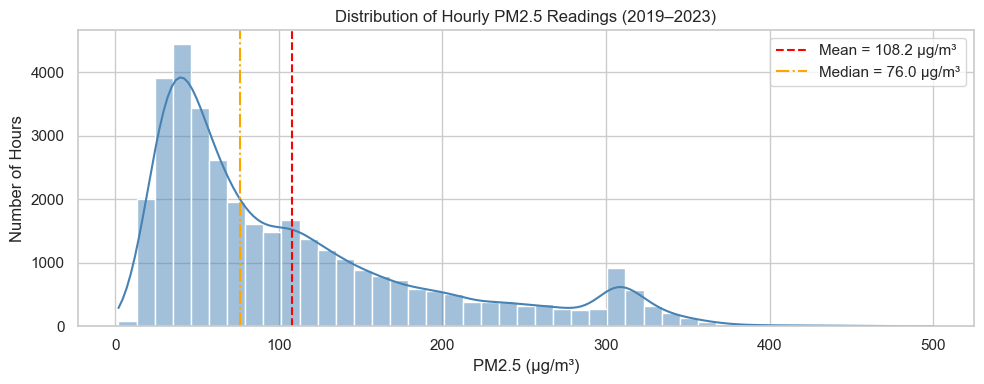

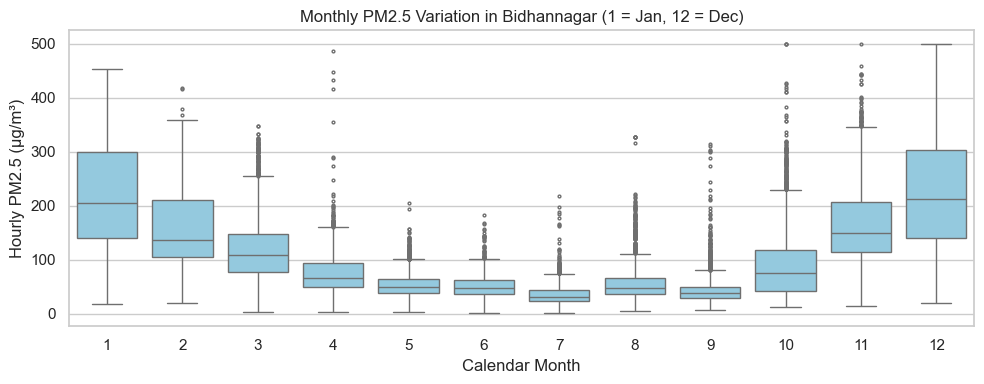

In [4]:
df_eda = df_hourly.dropna(subset=["pm25"]).copy()
df_eda["month"] = df_eda["date"].dt.month

monthly_summary = df_eda.groupby("month")["pm25"].agg(["count", "mean", "median", "min", "max"])
print("Monthly PM2.5 summary (2019–2023):")
display(monthly_summary.round(2))

# Plot 1: Distribution of hourly PM2.5
plt.figure(figsize=(10, 4))
sns.histplot(df_eda["pm25"], bins=45, kde=True, color="steelblue")
plt.axvline(df_eda["pm25"].mean(), color="red", linestyle="--", label=f"Mean = {df_eda['pm25'].mean():.1f} µg/m³")
plt.axvline(df_eda["pm25"].median(), color="orange", linestyle="-.", label=f"Median = {df_eda['pm25'].median():.1f} µg/m³")
plt.title("Distribution of Hourly PM2.5 Readings (2019–2023)")
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Number of Hours")
plt.legend()
plt.tight_layout()
plt.show()

# Plot 2: Monthly variation boxplot
plt.figure(figsize=(10, 4))
sns.boxplot(data=df_eda, x="month", y="pm25", color="skyblue", fliersize=2)
plt.title("Monthly PM2.5 Variation in Bidhannagar (1 = Jan, 12 = Dec)")
plt.xlabel("Calendar Month")
plt.ylabel("Hourly PM2.5 (µg/m³)")
plt.tight_layout()
plt.show()

## 6. Data Cleaning

Following the assignment instructions:
1. Check for duplicate `(date, hour)` timestamps and resolve any duplicates by taking their hourly mean before daily aggregation.
2. Sort chronologically by timestamp and leave missing values as `NaN` (never fill missing values from future readings).

In [5]:
duplicate_count = df_hourly["timestamp"].duplicated().sum()
print("Duplicate hourly timestamps found:", duplicate_count)

# Group by (date, hour) to resolve any duplicates safely before daily aggregation
df_hourly_clean = df_hourly.groupby(["date", "hour"], as_index=False)["pm25"].mean()
df_hourly_clean = df_hourly_clean.sort_values(["date", "hour"]).reset_index(drop=True)

print("Hourly rows after duplicate check and sorting:", len(df_hourly_clean))

Duplicate hourly timestamps found: 0
Hourly rows after duplicate check and sorting: 38280


## 7. Convert Hourly Data into Daily Data

We aggregate hourly readings to daily averages using the assignment's completeness rule:
1. Count distinct valid hours per date.
2. Reindex to a **complete daily calendar** from `2019-08-01` to `2023-12-31` so missing calendar dates appear explicitly.
3. Keep the daily mean PM2.5 **only if at least 18 valid hours** exist on that day; otherwise leave that day missing (`NaN`).

In [6]:
# Count valid hours and calculate daily mean for dates present in the CSV
daily_stats = df_hourly_clean.groupby("date")["pm25"].agg(
    valid_hours="count",
    raw_mean="mean"
)

# Reindex to a complete daily calendar (2019-08-01 to 2023-12-31)
all_dates = pd.date_range(start="2019-08-01", end="2023-12-31", freq="D")
daily = daily_stats.reindex(all_dates)
daily.index.name = "date"

# Dates absent from CSV get 0 valid hours
daily["valid_hours"] = daily["valid_hours"].fillna(0).astype(int)

# Apply the minimum 18-valid-hours rule; leave invalid days as NaN
daily["is_valid"] = daily["valid_hours"] >= 18
daily["pm25_mean"] = np.where(daily["is_valid"], daily["raw_mean"], np.nan)

# Yearly coverage summary
daily["year"] = daily.index.year
yearly_coverage = daily.groupby("year").agg(
    total_calendar_days=("valid_hours", "count"),
    valid_days_18h=("is_valid", "sum"),
    invalid_or_missing_days=("is_valid", lambda s: (~s).sum())
)
yearly_coverage["coverage_pct"] = (yearly_coverage["valid_days_18h"] / yearly_coverage["total_calendar_days"] * 100).round(1)

print("Total calendar days:", len(daily))
print("Valid days (>= 18 valid hours):", int(daily["is_valid"].sum()))
print("Invalid/missing days left as NaN:", int((~daily["is_valid"]).sum()))
display(yearly_coverage)

Total calendar days: 1614
Valid days (>= 18 valid hours): 1484
Invalid/missing days left as NaN: 130


,total_calendar_days,valid_days_18h,invalid_or_missing_days,coverage_pct
year,,,,
2019,153,110,43,71.9
2020,366,335,31,91.5
2021,365,352,13,96.4
2022,365,337,28,92.3
2023,365,350,15,95.9


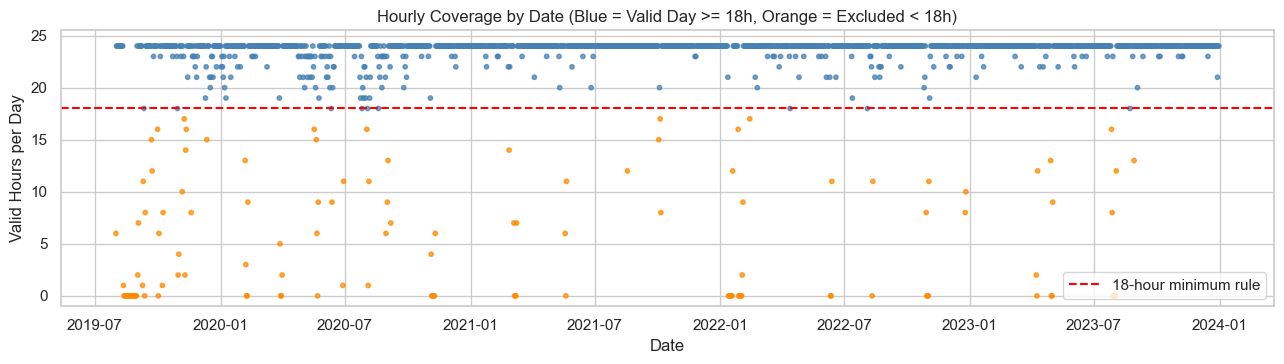

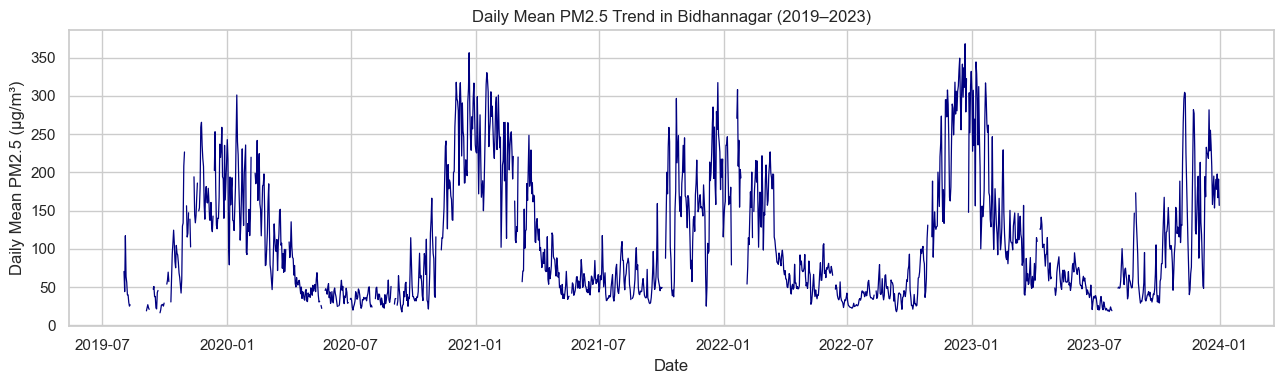

In [7]:
# Plot 1: Hourly coverage by date
plt.figure(figsize=(13, 3.8))
colors = np.where(daily["is_valid"], "steelblue", "darkorange")
plt.scatter(daily.index, daily["valid_hours"], c=colors, s=10, alpha=0.75)
plt.axhline(18, color="red", linestyle="--", label="18-hour minimum rule")
plt.title("Hourly Coverage by Date (Blue = Valid Day >= 18h, Orange = Excluded < 18h)")
plt.xlabel("Date")
plt.ylabel("Valid Hours per Day")
plt.ylim(-1, 25.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Plot 2: Daily PM2.5 trend
plt.figure(figsize=(13, 4))
plt.plot(daily.index, daily["pm25_mean"], color="navy", linewidth=0.9)
plt.title("Daily Mean PM2.5 Trend in Bidhannagar (2019–2023)")
plt.xlabel("Date")
plt.ylabel("Daily Mean PM2.5 (µg/m³)")
plt.tight_layout()
plt.show()

## 8. Feature Engineering

Each row represents the end of day $D$, predicting the next calendar day $D + 1$. Using only past and current observations through day $D$, we create:
- `pm25_today`: Day $D$ mean PM2.5
- `pm25_yesterday`: Day $D - 1$ mean PM2.5 (`shift(1)`)
- `pm25_2days_ago`: Day $D - 2$ mean PM2.5 (`shift(2)`)
- `pm25_roll7`: Trailing 7-day mean (`rolling(7).mean()`), requiring **all 7 consecutive calendar days** `[D-6 ... D]` to be valid so the rolling average never crosses missing days
- `month_sin`, `month_cos`: Cyclical encoding of calendar month $D$ (so December and January sit next to each other)

**Target:** `target_next_day` = Day $D + 1$ mean PM2.5 (`shift(-1)`). Rows missing any feature or the target are dropped without imputation.

In [8]:
df_features = pd.DataFrame(index=daily.index)
df_features.index.name = "date_D"

# Date being forecasted (D + 1)
df_features["forecast_date"] = df_features.index + pd.Timedelta(days=1)

# Features available at the end of day D
df_features["pm25_today"] = daily["pm25_mean"]
df_features["pm25_yesterday"] = daily["pm25_mean"].shift(1)
df_features["pm25_2days_ago"] = daily["pm25_mean"].shift(2)

# Trailing 7-day mean requiring 7 valid calendar days (default min_periods=7)
df_features["pm25_roll7"] = daily["pm25_mean"].rolling(7).mean()

# Cyclical encoding of calendar month (1 to 12)
df_features["month"] = df_features.index.month
df_features["month_sin"] = np.sin(2 * np.pi * df_features["month"] / 12)
df_features["month_cos"] = np.cos(2 * np.pi * df_features["month"] / 12)

# Target: next calendar day's PM2.5 mean (D + 1)
df_features["target_next_day"] = daily["pm25_mean"].shift(-1)

feature_cols = [
    "pm25_today",
    "pm25_yesterday",
    "pm25_2days_ago",
    "pm25_roll7",
    "month_sin",
    "month_cos",
]

print("Rows before dropping missing features/target:", len(df_features))
df_model = df_features.dropna(subset=feature_cols + ["target_next_day"]).copy()
print("Rows after dropping missing features/target: ", len(df_model))

# Preview first 5 aligned rows
df_model[["forecast_date", "pm25_today", "pm25_yesterday", "pm25_roll7", "target_next_day"]].head().round(2)

Rows before dropping missing features/target: 1614
Rows after dropping missing features/target:  1243


,forecast_date,pm25_today,pm25_yesterday,pm25_roll7,target_next_day
date_D,,,,,
2019-08-08,2019-08-09,40.04,40.04,61.78,30.21
2019-08-09,2019-08-10,30.21,40.04,56.01,25.29
2019-08-10,2019-08-11,25.29,30.21,53.30,27.04
2019-09-20,2019-09-21,43.04,21.67,37.38,45.75
2019-10-16,2019-10-17,83.58,107.96,87.06,75.38


## 9. Train, Validation and Test Split

We use a strict **chronological split** based on `forecast_date` (`D + 1`):
- **Training set:** Forecast dates up to `2021-12-31`
- **Validation set:** Forecast dates in `2022-01-01` to `2022-12-31` (for hyperparameter tuning and model selection)
- **Test set:** Forecast dates in `2023-01-01` to `2023-12-31` (the latest complete calendar year with strong coverage, held out until final evaluation)

In [9]:
train_df = df_model[df_model["forecast_date"] <= "2021-12-31"].copy()
val_df = df_model[(df_model["forecast_date"] >= "2022-01-01") & (df_model["forecast_date"] <= "2022-12-31")].copy()
test_df = df_model[df_model["forecast_date"] >= "2023-01-01"].copy()

split_table = pd.DataFrame([
    {"Split": "Train", "Start": train_df["forecast_date"].min().date(), "End": train_df["forecast_date"].max().date(), "Rows (N)": len(train_df)},
    {"Split": "Validation", "Start": val_df["forecast_date"].min().date(), "End": val_df["forecast_date"].max().date(), "Rows (N)": len(val_df)},
    {"Split": "Test", "Start": test_df["forecast_date"].min().date(), "End": test_df["forecast_date"].max().date(), "Rows (N)": len(test_df)},
])
display(split_table)

X_train, y_train = train_df[feature_cols], train_df["target_next_day"]
X_val, y_val = val_df[feature_cols], val_df["target_next_day"]
X_test, y_test = test_df[feature_cols], test_df["target_next_day"]

,Split,Start,End,Rows (N)
0,Train,2019-08-09,2021-12-31,634
1,Validation,2022-01-01,2022-12-24,290
2,Test,2023-01-03,2023-12-31,319


## 10. Persistence Baseline

The **Persistence baseline** simply predicts that tomorrow's PM2.5 will equal today's observed PM2.5 (`pm25_today`). Any useful machine learning model should be compared against this simple benchmark.

In [10]:
val_pred_persistence = val_df["pm25_today"]
val_mae_persistence = mean_absolute_error(y_val, val_pred_persistence)

print(f"Persistence Validation MAE (2022): {val_mae_persistence:.2f} µg/m³ (N = {len(val_df)})")

Persistence Validation MAE (2022): 16.29 µg/m³ (N = 290)


## 11. Ridge Regression

Because Ridge Regression penalizes coefficient magnitudes, we standardize the features using `StandardScaler` fit **only on the training data** (`fit_transform` on `X_train`, `transform` on `X_val`). We test several `alpha` values and pick the one with the lowest **Validation MAE**.

In [11]:
# Scale features using training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# Tune regularization strength alpha on validation set
alphas = [0.1, 1.0, 10.0, 50.0, 100.0]
ridge_results = []

for alpha in alphas:
    model = Ridge(alpha=alpha, random_state=RANDOM_STATE)
    model.fit(X_train_scaled, y_train)
    val_pred = model.predict(X_val_scaled)
    mae = mean_absolute_error(y_val, val_pred)
    ridge_results.append({"alpha": alpha, "Validation MAE (µg/m³)": round(mae, 3)})

ridge_tuning_table = pd.DataFrame(ridge_results).sort_values("Validation MAE (µg/m³)").reset_index(drop=True)
display(ridge_tuning_table)

best_alpha = float(ridge_tuning_table.loc[0, "alpha"])
val_mae_ridge = float(ridge_tuning_table.loc[0, "Validation MAE (µg/m³)"])
print(f"Best Ridge alpha = {best_alpha} with Validation MAE = {val_mae_ridge:.2f} µg/m³")

,alpha,Validation MAE (µg/m³)
0,0.1,16.850
1,1.0,16.867
2,10.0,17.054
3,50.0,17.751
4,100.0,18.600


Best Ridge alpha = 0.1 with Validation MAE = 16.85 µg/m³


## 12. Random Forest Regression

Random Forest can capture non-linear relationships without requiring feature scaling. We test a small, manageable grid of `max_depth` and `min_samples_leaf` values (`n_estimators=100`, `random_state=42`) and select the best configuration using **Validation MAE**.

In [12]:
rf_results = []

for depth in [4, 6, 8]:
    for min_leaf in [5, 10]:
        rf = RandomForestRegressor(
            n_estimators=100,
            max_depth=depth,
            min_samples_leaf=min_leaf,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
        rf.fit(X_train, y_train)
        val_pred = rf.predict(X_val)
        mae = mean_absolute_error(y_val, val_pred)
        rf_results.append({
            "max_depth": depth,
            "min_samples_leaf": min_leaf,
            "Validation MAE (µg/m³)": round(mae, 3)
        })

rf_tuning_table = pd.DataFrame(rf_results).sort_values("Validation MAE (µg/m³)").reset_index(drop=True)
display(rf_tuning_table)

best_depth = int(rf_tuning_table.loc[0, "max_depth"])
best_leaf = int(rf_tuning_table.loc[0, "min_samples_leaf"])
val_mae_rf = float(rf_tuning_table.loc[0, "Validation MAE (µg/m³)"])
print(f"Best Random Forest: max_depth={best_depth}, min_samples_leaf={best_leaf} with Validation MAE = {val_mae_rf:.2f} µg/m³")

,max_depth,min_samples_leaf,Validation MAE (µg/m³)
0,4,5,17.012
1,4,10,17.075
2,6,5,17.174
3,6,10,17.223
4,8,10,17.245
5,8,5,17.405


Best Random Forest: max_depth=4, min_samples_leaf=5 with Validation MAE = 17.01 µg/m³


## 13. Model Evaluation

First, we compare Validation MAE (2022) to **choose our preferred ML model strictly on validation data** (without peeking at the 2023 test set).  
Next, we refit the tuned Ridge and Random Forest models on all pre-test data (`Train + Validation`, 2019–2022) and evaluate all three approaches on **identical 2023 test forecast dates** for:
1. **Full Test Year (2023)**
2. **Winter Subset (December–February 2023)**

In [13]:
# Step 1: Select the preferred ML model using 2022 Validation MAE only
if val_mae_ridge <= val_mae_rf:
    preferred_model_name = f"Ridge Regression (alpha={best_alpha})"
    preferred_pred_col = "pred_ridge"
else:
    preferred_model_name = f"Random Forest (depth={best_depth}, leaf={best_leaf})"
    preferred_pred_col = "pred_rf"

print(f"Validation MAE (2022) -> Persistence: {val_mae_persistence:.2f} | Ridge: {val_mae_ridge:.2f} | Random Forest: {val_mae_rf:.2f} µg/m³")
print(f"Preferred ML model selected from Validation data: {preferred_model_name}")

# Step 2: Refit tuned Ridge and Random Forest on Train + Validation (2019–2022)
train_val_df = pd.concat([train_df, val_df], axis=0)
X_train_val = train_val_df[feature_cols]
y_train_val = train_val_df["target_next_day"]

# Scale using Train+Validation only, then transform Test
final_scaler = StandardScaler()
X_tv_scaled = final_scaler.fit_transform(X_train_val)
X_test_scaled = final_scaler.transform(X_test)

final_ridge = Ridge(alpha=best_alpha, random_state=RANDOM_STATE)
final_ridge.fit(X_tv_scaled, y_train_val)

final_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=best_depth,
    min_samples_leaf=best_leaf,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
final_rf.fit(X_train_val, y_train_val)

# Step 3: Predict on identical 2023 test forecast dates
results_df = test_df[["forecast_date", "pm25_today", "target_next_day"]].copy()
results_df = results_df.rename(columns={"target_next_day": "actual"})
results_df["pred_persistence"] = results_df["pm25_today"]
results_df["pred_ridge"] = final_ridge.predict(X_test_scaled)
results_df["pred_rf"] = final_rf.predict(X_test)

# Subset for December-February 2023
djf_mask = results_df["forecast_date"].dt.month.isin([12, 1, 2])
results_djf = results_df[djf_mask]

comparison_table = pd.DataFrame([
    {
        "Model": "Persistence Baseline",
        "Full Test MAE (µg/m³)": round(mean_absolute_error(results_df["actual"], results_df["pred_persistence"]), 2),
        "Full Test N": len(results_df),
        "Dec–Feb MAE (µg/m³)": round(mean_absolute_error(results_djf["actual"], results_djf["pred_persistence"]), 2),
        "Dec–Feb N": len(results_djf),
    },
    {
        "Model": f"Ridge Regression (alpha={best_alpha})",
        "Full Test MAE (µg/m³)": round(mean_absolute_error(results_df["actual"], results_df["pred_ridge"]), 2),
        "Full Test N": len(results_df),
        "Dec–Feb MAE (µg/m³)": round(mean_absolute_error(results_djf["actual"], results_djf["pred_ridge"]), 2),
        "Dec–Feb N": len(results_djf),
    },
    {
        "Model": f"Random Forest (depth={best_depth}, leaf={best_leaf})",
        "Full Test MAE (µg/m³)": round(mean_absolute_error(results_df["actual"], results_df["pred_rf"]), 2),
        "Full Test N": len(results_df),
        "Dec–Feb MAE (µg/m³)": round(mean_absolute_error(results_djf["actual"], results_djf["pred_rf"]), 2),
        "Dec–Feb N": len(results_djf),
    },
])

print("\n2023 Test Set MAE Comparison (identical forecast dates):")
display(comparison_table)

Validation MAE (2022) -> Persistence: 16.29 | Ridge: 16.85 | Random Forest: 17.01 µg/m³
Preferred ML model selected from Validation data: Ridge Regression (alpha=0.1)

2023 Test Set MAE Comparison (identical forecast dates):


,Model,Full Test MAE (µg/m³),Full Test N,Dec–Feb MAE (µg/m³),Dec–Feb N
0,Persistence Baseline,22.66,319,39.18,88
1,Ridge Regression (alpha=0.1),21.84,319,36.67,88
2,"Random Forest (depth=4, leaf=5)",22.67,319,37.63,88


## 14. Actual vs Predicted Visualization

We plot actual vs. predicted daily mean PM2.5 across the 2023 test year and mark the **three largest absolute prediction errors** of the validation-selected model.

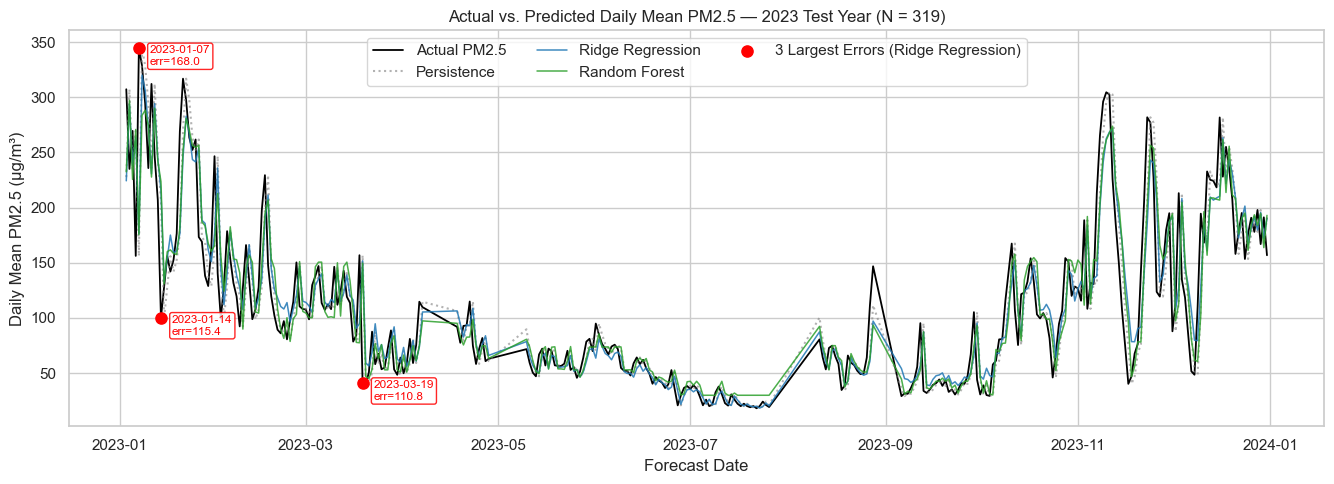

In [14]:
results_df["abs_err_selected"] = (results_df["actual"] - results_df[preferred_pred_col]).abs()
results_df["abs_err_persistence"] = (results_df["actual"] - results_df["pred_persistence"]).abs()

top3_errors = results_df.sort_values("abs_err_selected", ascending=False).head(3).copy()

plt.figure(figsize=(13.5, 5))
plt.plot(results_df["forecast_date"], results_df["actual"], color="black", linewidth=1.3, label="Actual PM2.5")
plt.plot(results_df["forecast_date"], results_df["pred_persistence"], color="gray", linestyle=":", alpha=0.6, label="Persistence")
plt.plot(results_df["forecast_date"], results_df["pred_ridge"], color="tab:blue", linewidth=1.1, alpha=0.85, label="Ridge Regression")
plt.plot(results_df["forecast_date"], results_df["pred_rf"], color="tab:green", linewidth=1.1, alpha=0.85, label="Random Forest")

# Mark the 3 largest errors of the preferred ML model
plt.scatter(top3_errors["forecast_date"], top3_errors["actual"], color="red", s=65, zorder=5,
            label=f"3 Largest Errors ({preferred_model_name.split(' (')[0]})")

for _, row in top3_errors.iterrows():
    plt.annotate(
        f"{row['forecast_date'].strftime('%Y-%m-%d')}\nerr={row['abs_err_selected']:.1f}",
        xy=(row["forecast_date"], row["actual"]),
        xytext=(8, -12),
        textcoords="offset points",
        fontsize=8.5,
        color="red",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="red", alpha=0.85)
    )

plt.title(f"Actual vs. Predicted Daily Mean PM2.5 — 2023 Test Year (N = {len(results_df)})")
plt.xlabel("Forecast Date")
plt.ylabel("Daily Mean PM2.5 (µg/m³)")
plt.legend(loc="upper center", ncol=3)
plt.tight_layout()
plt.show()

## 15. Error Analysis

We inspect the three largest errors of our validation-selected model, examine the surrounding days (`±2` days), and zoom in on the largest single error episode (`±7` days) to see whether it was a sudden pollution spike or clearance.

In [15]:
print(f"Three largest absolute errors for {preferred_model_name}:")
display(top3_errors[[
    "forecast_date", "actual", "pred_persistence", "pred_ridge", "pred_rf",
    "abs_err_selected", "abs_err_persistence"
]].round(2))

# Inspect surrounding days for each of the 3 largest errors
results_by_date = results_df.set_index("forecast_date")

for i, (_, err_row) in enumerate(top3_errors.iterrows(), start=1):
    err_date = err_row["forecast_date"]
    start_d = err_date - pd.Timedelta(days=2)
    end_d = err_date + pd.Timedelta(days=2)

    surrounding = daily.loc[start_d:end_d, ["valid_hours", "pm25_mean"]].copy()
    preds_window = results_by_date.reindex(surrounding.index)[["pred_persistence", "pred_ridge", "pred_rf", "abs_err_selected"]]
    table_window = pd.concat([surrounding, preds_window], axis=1)

    print(f"\nError #{i}: {err_date.strftime('%Y-%m-%d')} | Actual = {err_row['actual']:.1f}, "
          f"Predicted = {err_row[preferred_pred_col]:.1f}, |Error| = {err_row['abs_err_selected']:.1f} µg/m³")
    display(table_window.round(2))

Three largest absolute errors for Ridge Regression (alpha=0.1):


,forecast_date,actual,pred_persistence,pred_ridge,pred_rf,abs_err_selected,abs_err_persistence
date_D,,,,,,,
2023-01-06,2023-01-07,344.29,156.29,176.32,175.47,167.98,188.00
2023-01-13,2023-01-14,100.12,206.92,215.49,223.61,115.37,106.79
2023-03-18,2023-03-19,41.00,156.88,151.82,149.72,110.82,115.88



Error #1: 2023-01-07 | Actual = 344.3, Predicted = 176.3, |Error| = 168.0 µg/m³


,valid_hours,pm25_mean,pred_persistence,pred_ridge,pred_rf,abs_err_selected
date_D,,,,,,
2023-01-05,24,269.54,235.08,238.07,225.60,31.47
2023-01-06,24,156.29,269.54,263.56,270.85,107.27
2023-01-07,24,344.29,156.29,176.32,175.47,167.98
2023-01-08,24,328.58,344.29,320.09,283.62,8.49
2023-01-09,24,294.25,328.58,306.22,288.26,11.97



Error #2: 2023-01-14 | Actual = 100.1, Predicted = 215.5, |Error| = 115.4 µg/m³


,valid_hours,pm25_mean,pred_persistence,pred_ridge,pred_rf,abs_err_selected
date_D,,,,,,
2023-01-12,24,246.71,312.08,294.25,290.02,47.54
2023-01-13,24,206.92,246.71,244.32,242.38,37.40
2023-01-14,24,100.12,206.92,215.49,223.61,115.37
2023-01-15,24,127.92,100.12,133.33,130.85,5.41
2023-01-16,24,156.00,127.92,154.52,160.12,1.48



Error #3: 2023-03-19 | Actual = 41.0, Predicted = 151.8, |Error| = 110.8 µg/m³


,valid_hours,pm25_mean,pred_persistence,pred_ridge,pred_rf,abs_err_selected
date_D,,,,,,
2023-03-17,22,84.45,78.62,90.71,77.89,6.25
2023-03-18,24,156.88,84.45,94.95,77.54,61.92
2023-03-19,24,41.00,156.88,151.82,149.72,110.82
2023-03-20,24,39.62,41.00,59.24,46.91,19.62
2023-03-21,24,50.96,39.62,56.55,45.24,5.59


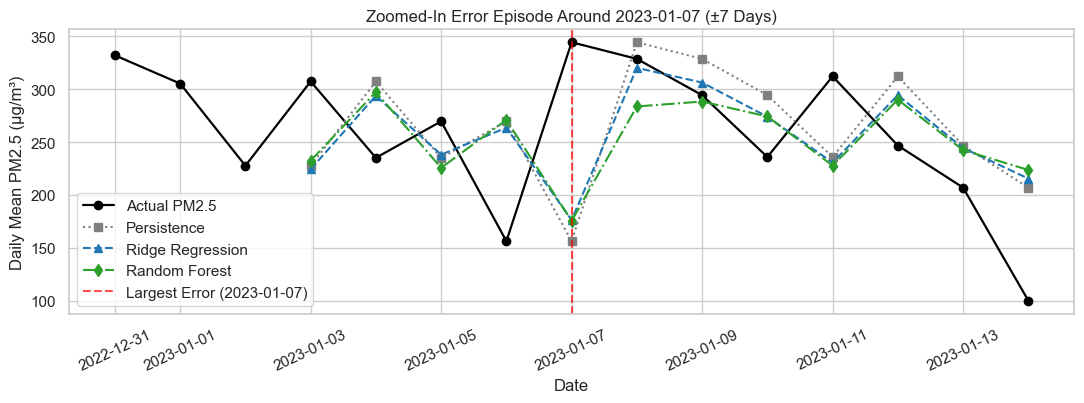

In [16]:
# Zoomed-in view of the largest error episode (±7 days)
worst_date = top3_errors.iloc[0]["forecast_date"]
zoom_actual = daily.loc[worst_date - pd.Timedelta(days=7): worst_date + pd.Timedelta(days=7), "pm25_mean"]
zoom_preds = results_by_date.reindex(zoom_actual.index)

plt.figure(figsize=(11, 4.2))
plt.plot(zoom_actual.index, zoom_actual.values, marker="o", color="black", linewidth=1.6, label="Actual PM2.5")
plt.plot(zoom_preds.index, zoom_preds["pred_persistence"], marker="s", linestyle=":", color="gray", label="Persistence")
plt.plot(zoom_preds.index, zoom_preds["pred_ridge"], marker="^", linestyle="--", color="tab:blue", label="Ridge Regression")
plt.plot(zoom_preds.index, zoom_preds["pred_rf"], marker="d", linestyle="-.", color="tab:green", label="Random Forest")
plt.axvline(worst_date, color="red", linestyle="--", alpha=0.7, label=f"Largest Error ({worst_date.strftime('%Y-%m-%d')})")

plt.title(f"Zoomed-In Error Episode Around {worst_date.strftime('%Y-%m-%d')} (±7 Days)")
plt.xlabel("Date")
plt.ylabel("Daily Mean PM2.5 (µg/m³)")
plt.xticks(rotation=25)
plt.legend()
plt.tight_layout()
plt.show()

## 16. Conclusion

Below we print the final numerical summary directly answering the research question: *"Can yesterday's readings help forecast tomorrow's PM2.5 in Bidhannagar?"*

In [17]:
pers_full = comparison_table.loc[0, "Full Test MAE (µg/m³)"]
ridge_full = comparison_table.loc[1, "Full Test MAE (µg/m³)"]
rf_full = comparison_table.loc[2, "Full Test MAE (µg/m³)"]

pers_djf = comparison_table.loc[0, "Dec–Feb MAE (µg/m³)"]
ridge_djf = comparison_table.loc[1, "Dec–Feb MAE (µg/m³)"]
rf_djf = comparison_table.loc[2, "Dec–Feb MAE (µg/m³)"]

print(f"Preferred ML model (selected on 2022 Validation MAE): {preferred_model_name}")
print(f"2023 Full Test MAE (N={len(results_df)}): Persistence={pers_full:.2f}, Ridge={ridge_full:.2f}, Random Forest={rf_full:.2f} µg/m³")
print(f"2023 Dec–Feb MAE   (N={len(results_djf)}): Persistence={pers_djf:.2f}, Ridge={ridge_djf:.2f}, Random Forest={rf_djf:.2f} µg/m³")

Preferred ML model (selected on 2022 Validation MAE): Ridge Regression (alpha=0.1)
2023 Full Test MAE (N=319): Persistence=22.66, Ridge=21.84, Random Forest=22.67 µg/m³
2023 Dec–Feb MAE   (N=88): Persistence=39.18, Ridge=36.67, Random Forest=37.63 µg/m³


### Summary of Findings
1. **Answer to the Research Question:** Yes — yesterday's PM2.5 reading is the single strongest predictor of tomorrow's PM2.5. Adding multi-day lags (`D-1`, `D-2`), the strict 7-day trailing average, and calendar month seasonality in **Ridge Regression** slightly reduces test error over the Persistence baseline across the full 2023 test year and improves winter (December–February) accuracy more noticeably.
2. **Why Large Errors Still Happen:** As seen in the zoomed-in plot around `2023-01-07`, the worst errors occur during abrupt single-day spikes or sudden clearances. Because the dataset contains only past PM2.5 readings (without weather inputs like wind speed or rainfall), models driven solely by past concentrations cannot anticipate sudden meteorological shifts.
3. **Key Limitations:** The CSV lacks in-file station/unit headers, has no data before August 2019, and caps integer readings at `500`. Therefore, forecasts should be shown alongside an expected error margin rather than treated as exact alerts during rapid weather changes.